In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree

from sklearn.ensemble import GradientBoostingRegressor

#                                   Theory
```js
        Read the complete theory of Gradient Boosting in Regression in "1. Gradient Boosting Regression Theory.pdf" and "2. Gradient Boosting Regression Math.pdf" from Theory folder.
```

#                                   Dataset creation and Split into training and testing set.

     iq        cg  salary($)
343  18  3.724155       5380
69   20  2.505015       6861
880  32  2.995187       8741
367  39  2.466504       6914
500  68  3.105230       8071
373  53  3.614101       5403
102  84  2.933464       5905
991  62  3.406412       7363
814  23  3.216530       3400
722  55  2.119584       3478


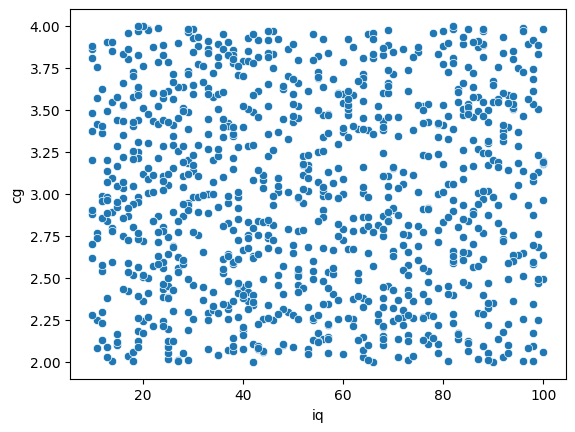

In [15]:
# Dataset creation and displaying 10 random rows.
df = pd.DataFrame(data = {
        "iq": np.random.randint(low = 10, high = 101, size = 1000), # 10 to 100.
        "cg": np.random.uniform(low = 2, high = 4, size = 1000), # 2 to 3.999..
        "salary($)": np.random.randint(low = 1000, high = 10_001, size = 1000) # 1000 to 10_000.
})
print(df.sample(10))

# Dataset split into training and testing set.
X, y = df.iloc[:, :-1].values, df.iloc[:, -1].values
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Dataset visualization to see the pattern and there is no pattern!
sns.scatterplot(data = df, x = 'iq', y = 'cg')
plt.show()

# Creating Gradient Boosting Regression from Scratch.

In [ ]:
class GradientBoostingRegression: # loss_function = "squared_error" used for each tree, see fit().
    # res = residual_error. pred = predicted.
    def __init__(self, learning_rate: float = 0.1, n_estimators: int = 0, max_depth: int = 0, random_state: int|None = None):
        self.learning_rate = learning_rate
        self.n_estimators = n_estimators
        self.max_depth_for_each_tree = max_depth
        self.random_state_for_each_tree = random_state

        self.base_model_pred = None
        self.tree_models = np.full(shape = (n_estimators), fill_value = None)
    
    def fit(self, x_train: np.ndarray, y_train: np.ndarray):
        self.base_model_pred = y_train.mean()
        prev_model_residual_error = y_train - self.base_model_pred
        pred_salary_for_current_model = self.base_model_pred

        for m in range(1, self.n_estimators + 1):
            cur_tree = DecisionTreeRegressor(criterion = 'squared_error', max_depth = self.max_depth_for_each_tree,
                                             random_state = self.random_state_for_each_tree)
            cur_tree.fit(X = x_train, y = prev_model_residual_error)
            self.tree_models[m-1] = cur_tree # collecting all the trained trees.

            pred_salary_for_current_model += (self.learning_rate * cur_tree.predict(x_train))
            prev_model_residual_error = y_train - pred_salary_for_current_model

    def predict(self, x_test: np.ndarray):
        # all_models_predicted_residual_error = [[model1's res error], [model2's res error], [model3's res error], ...]
        all_models_pred_res = np.full(shape = (x_test.shape[0], self.n_estimators), fill_value = None)

        # Assigning each model's Residual Error for all the rows of x_test.
        for model_no in range(self.n_estimators):
            all_models_pred_res[:, model_no] = self.tree_models[model_no].predict(x_test) # ... = 1D Numpy Array.
        
        #      Base_model_pred_y    + Σ(learning_rate * model_i_res)
        return self.base_model_pred + (self.learning_rate * all_models_pred_res).sum(axis = 1)

Our GBR vs Sklearn GBR :

 5410.122,  5410.122.
 5599.506,  5599.506.
 5432.938,  5432.938.
 5745.058,  5745.058.
 5448.802,  5448.802.


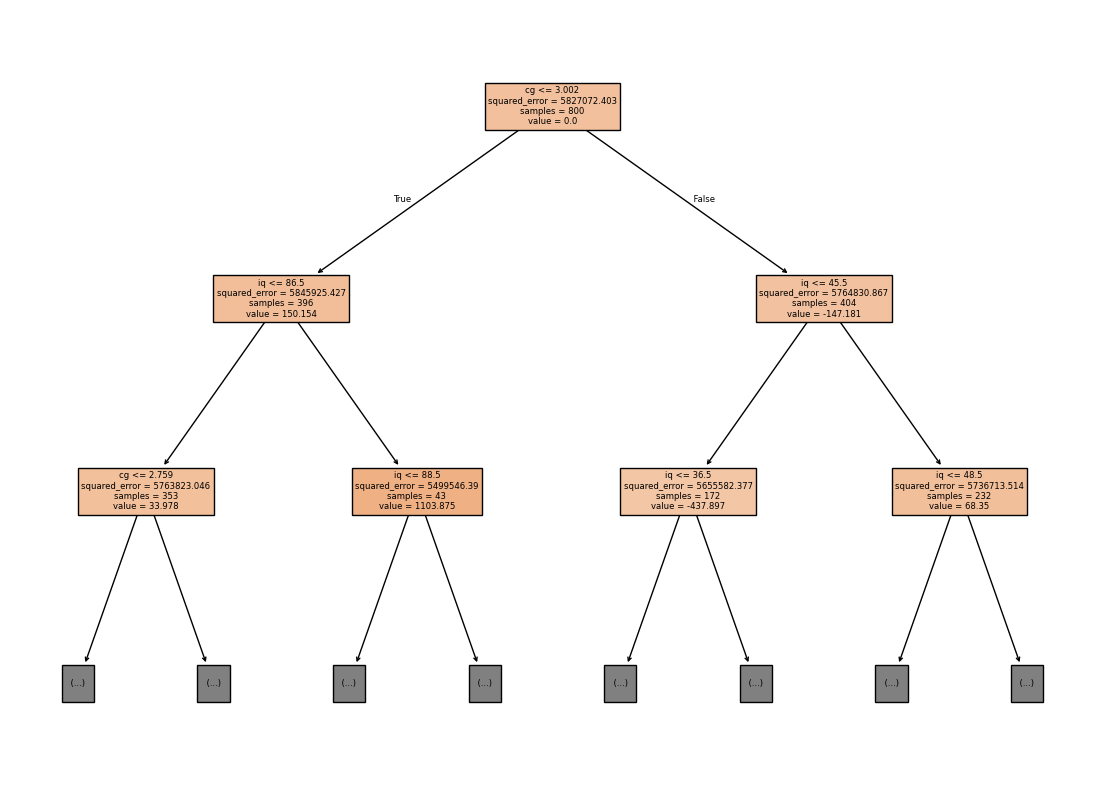

In [27]:
# Our custom GradientBoostingRegression.
gbr = GradientBoostingRegression(learning_rate = 0.1, n_estimators = 3, max_depth = 10, random_state = 42)
gbr.fit(x_train = x_train, y_train = y_train)
gbr_pred = gbr.predict(x_test = x_test[:5])

# By default in Sklearn's GradientBoostingRegressor, loss = 'squared_error'.
gbr1 = GradientBoostingRegressor(learning_rate = 0.1, n_estimators = 3, max_depth = 10, random_state = 42,
                                 criterion = 'squared_error') # This criterion is for each Tree.
gbr1.fit(X = x_train, y = y_train)
gbr1_predict = gbr1.predict(x_test[:5])

# Comparing the prediction result of Our custom gbr and Sklearn gbr1. THEY ARE SAMEEEE!!!
print("Our GBR vs Sklearn GBR :\n")
for i in range(gbr_pred.shape[0]):
    print(f"{gbr_pred[i]: .3f}, {gbr1_predict[i]: .3f}.")

# Since the Prediction (on Output column) of the last Tree Model is the Prediction of GradientBoosting, lets plot the tree.
plt.figure(figsize = (14, 10))
plot_tree(decision_tree = gbr1.estimators_[-1][0], feature_names = df.columns[:-1], filled = True, max_depth = 2)
plt.show() # max_depth = 2 because its a loooong tree. So displayed clearly only till depth 2.

# fit() method with more details.
```js
            This is to show what is happening for each Tree Model inside GradientBoostingRegressor.
```

In [ ]:
def GBR_fit(X: pd.DataFrame, y: pd.Series, n_estimators: int, lr: float):
    df = pd.concat([X, y], axis=1)

    # For the Base Model which is not a Machine Learning Model but a Box of calculations.
    df['pred_salary_0'] = df['salary($)'].mean()
    df['res_0'] = df['salary($)'] - df['pred_salary_0']
    pred_salary_for_current_model = df['pred_salary_0'].values # pred = predicted.

    # For the Tree models.
    for i in range(1, n_estimators + 1):
        cur_tree = DecisionTreeRegressor(max_depth = 10, random_state = 42).fit(X, df[f'res_{i-1}'])
        df[f'pred_res_{i}'] = cur_tree.predict(X) # whatever tree predicted.
        pred_salary_for_current_model += (lr * df[f'pred_res_{i}']) # sum_of_all_pred_salary.
        df[f'res_{i}'] = df['salary($)'] - pred_salary_for_current_model
        df[f"pred_salary_{i}"] = pred_salary_for_current_model

    return df

GBR_fit(X = df[['iq', 'cg']], y = df['salary($)'], n_estimators = 3, lr = 0.1)

,iq,cg,salary($),pred_salary_0,res_0,pred_res_1,res_1,pred_salary_1,pred_res_2,res_2,pred_salary_2,pred_res_3,res_3,pred_salary_3
0,98,3.957888,3488,5014.737410,-2094.29,-2094.290000,-1884.861000,5372.861000,-1884.861000,-1696.374900,5184.374900,-1696.374900,-1526.737410,5014.737410
1,19,3.481842,9518,5976.352717,3935.71,58.381400,3929.871860,5588.128140,-52.917878,3935.163648,5582.836352,3935.163648,3541.647283,5976.352717
2,56,3.799937,4535,5298.474410,-1047.29,-1047.290000,-942.561000,5477.561000,-942.561000,-848.304900,5383.304900,-848.304900,-763.474410,5298.474410
3,61,2.082377,1771,5382.810134,-3811.29,-1970.290000,-3614.261000,5385.261000,49.030774,-3619.164077,5390.164077,-73.539430,-3611.810134,5382.810134
4,34,3.533199,8874,5911.952717,3291.71,58.381400,3285.871860,5588.128140,-52.917878,3291.163648,5582.836352,3291.163648,2962.047283,5911.952717
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,29,3.946526,4162,5455.428577,-1420.29,-468.123333,-1373.477667,5535.477667,-421.311000,-1331.346567,5493.346567,-379.179900,-1293.428577,5455.428577
996,72,3.186001,1191,5536.072414,-4391.29,58.381400,-4397.128140,5588.128140,-52.917878,-4391.836352,5582.836352,-467.639382,-4345.072414,5536.072414
997,20,2.115476,1852,5186.844650,-3730.29,-2747.290000,-3455.561000,5307.561000,-1087.686000,-3346.792400,5198.792400,-119.477497,-3334.844650,5186.844650
998,24,3.021552,9497,5748.881288,3914.71,58.381400,3908.871860,5588.128140,-52.917878,3914.163648,5582.836352,1660.449362,3748.118712,5748.881288
